# NutriScan: AI-Powered Food Detection & Classification
### Capstone Project (CV) | Milestone 1: Data Understanding, EDA, Food Detection and Dataset Preparation

# Problem Statement

## Business Context

In today's fast-paced world, maintaining a balanced diet is a challenge for many people. Individuals struggle to track what they eat accurately, which leads to inconsistent nutritional habits and difficulty meeting health goals. Manual meal logging is time-consuming, error-prone and offers no real-time insight.

**NutriScan** is a smart food recognition system that uses image analysis and machine learning to identify food items from a photo and return real-time nutritional information (calories, macronutrients, portion size). It also suggests healthier alternatives based on user preferences and goals.

## Objective

As the Data Scientist at NutriScan, build an AI-powered food detection and classification system that:

1. **Detects and locates** food items in user-captured images (object detection).
2. **Classifies** each detected item into a food type (image classification).

These two capabilities unlock the downstream business outcomes (not built in this milestone):

- Personalised dietary recommendations and healthier meal alternatives from patterns in user food choices.
- Integration with health-tracking apps so users can monitor calorie intake and nutritional balance over time.
- Effortless tracking: one photo replaces manual logging.

## Why this matters (rationale for the report)

| Pain point today | What NutriScan changes | Value to the company |
|---|---|---|
| Manual logging is slow and users quit | One photo, instant result | Higher engagement and retention |
| Self-reported intake is inaccurate | Image-based identification | More trustworthy data, better recommendations |
| Generic diet advice | Personalised suggestions from logged habits | Differentiation, premium-tier potential |
| Siloed health data | Integration with health apps | Partnerships and ecosystem reach |

**Proposed success targets (to be agreed with stakeholders):** usable food crop for at least 90% of images; classification top-1 accuracy of at least 85% (Milestone 2).

## Milestone 1 Scope and Rubric Map (20 points)

| Rubric item | Pts | Notebook section | Report section |
|---|---|---|---|
| Introduction of the business problem | 2 | Problem Statement (this section) | 1. Business problem and rationale |
| Exploratory Data Analysis | 4 | Section 3 | 2. Data overview, 3. Key EDA findings |
| Object Detection (detect, crop, preprocess, build dataset) | 10 | Sections 4 and 5 | 4. Detection and preprocessing approach |
| Actionable Insights | 4 | Section 6 | 5. Insights and risks |
| Plan for the classification phase | - | Section 7 | 6. Methodology, 7. Next steps |

## Analytical Problem Framing

| Business question | Analytical task | Method | Output / metric |
|---|---|---|---|
| Where is the food in the photo? | Object detection | Zero-shot detector (OWL-ViT) with text prompts, because Food-101 has class labels but **no bounding boxes** | Boxes, detection rate, confidence |
| What food is it? | Image classification | Transfer learning (Milestone 2) | Top-1/Top-5 accuracy, macro-F1 |
| Is the data fit for training? | EDA and data quality | Class balance, sizes, brightness, blur, duplicates | Insights and cleaning decisions |

## Dataset

**Food-101 subset**: 17 food categories organised as class folders of JPEG images (the full public release has 101 categories with 1,000 images per class, with training images deliberately left slightly noisy). Your copy is 772 MB, so it is probably a reduced or resized version. **This notebook discovers the actual structure instead of assuming it.**

## Project Design (pipeline)

```
Photo -> [Detector: finds food region] -> crop (+5% padding, squared)
      -> resize 224x224 -> save as classification dataset (train/val/test)
      -> [Classifier, Milestone 2] -> food label -> nutrition lookup -> recommendations
```

# Instructions

## Please read the instructions carefully before starting

- Run cells **sequentially from the top**. Use a **GPU runtime** (Runtime > Change runtime type > T4 GPU).
- Edit settings **only in the Configuration cell**. The most important are `DRIVE_ZIP_PATH` and `MAX_PER_CLASS`.
- Because the dataset is large, do a **smoke test first** with `MAX_PER_CLASS = 10`, then raise it (e.g. 150, or `None` for everything).
- Detections are checkpointed to Google Drive, so if Colab disconnects you can re-run and it resumes.
- Every figure is saved to `figures/` and key numbers are stored in the `R` dictionary, then written to `milestone1_results.json`. Use these when writing the PDF report.
- After each major output, write your observations in the markdown cells marked **Observations**.
- Final submission: HTML export of this notebook (see the last cell) and a PDF business report.

# 1. Installing and Importing Libraries

In [1]:
# Dependencies.
#   Colab  -> installs the one package Colab does not already ship.
#   Local  -> nothing to do, setup_local.sh already built the environment.
# NOTE: transformers is intentionally NOT pinned to an old version; older
# releases do not have wheels for current Python versions and will fail.
import sys
if "google.colab" in sys.modules:
    %pip install -q --upgrade "transformers>=4.57"
else:
    print("Local run detected - using packages from your virtual environment.")


Local run detected - using packages from your virtual environment.


**Note:** If you later see a numpy/binary-compatibility error, restart the runtime once and run from the next cell.

In [2]:
import os, sys, json, math, time, random, shutil, hashlib, zipfile, subprocess, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from scipy import ndimage
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import nms
from torchvision import datasets, transforms

warnings.filterwarnings("ignore")      # keep the submitted notebook clean
sns.set_style("whitegrid")

# On a CPU-only machine, let PyTorch use every core (big speed-up for the detector).
torch.set_num_threads(os.cpu_count() or 4)
print(f"PyTorch {torch.__version__} | CUDA available: {torch.cuda.is_available()} | threads: {torch.get_num_threads()}")

PyTorch 2.14.1+cpu | CUDA available: False | threads: 8


## Configuration
All tunable settings live here. Each has a short comment describing what to change.

In [3]:
IN_COLAB = "google.colab" in sys.modules
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---- Paths: auto-detects Colab vs a local machine ---------------------------
if IN_COLAB:
    # Upload Food_101.zip to this location in your Google Drive first.
    DRIVE_ZIP_PATH = "/content/drive/MyDrive/Food_101.zip"
    EXTRACT_DIR = Path("/content/food101_raw")              # fast local disk, NOT Drive
    WORK_DIR    = Path("/content/nutriscan")
    PERSIST_DIR = Path("/content/drive/MyDrive/NutriScan_M1")   # survives disconnects
else:
    # Local run: the dataset is already unzipped, so point straight at it.
    # <-- CHANGE THIS if your Food_101 folder lives somewhere else.
    LOCAL_DATA_DIR = Path("/home/moti/Downloads/Food_101/Food_101")
    DRIVE_ZIP_PATH = None
    EXTRACT_DIR = LOCAL_DATA_DIR
    WORK_DIR    = Path.cwd() / "outputs"
    PERSIST_DIR = WORK_DIR / "persist"

CROP_DIR    = WORK_DIR / "cropped"                   # cropped + resized images
DATASET_DIR = WORK_DIR / "classification_dataset"    # train/val/test folders
FIG_DIR     = WORK_DIR / "figures"                   # figures for the PDF report

# ---- Hardware ---------------------------------------------------------------
HAS_GPU   = torch.cuda.is_available()
# DataLoader worker processes. 0 on a local run is deliberate:
# Python 3.12+ uses the 'forkserver' start method on Linux, which breaks
# DataLoader workers inside a notebook. On CPU the model forward pass
# dominates anyway, so background loading would buy almost nothing.
N_WORKERS = 2 if IN_COLAB else 0

# ---- Data volume controls ---------------------------------------------------
# Images per class to process.  10 = smoke test, 400 = recommended, None = all.
# 400 is deliberate: the smallest class has 256 images, so the real class
# imbalance survives the cap instead of being flattened away.
MAX_PER_CLASS    = 400
EDA_STATS_SAMPLE = 3000    # images used for brightness/blur statistics
SWEEP_PER_CLASS  = 15      # images per class for the detection-threshold sweep

# ---- Detector ---------------------------------------------------------------
# Do NOT switch to owlv2-base-patch16-ensemble on CPU: it is ~10x slower.
DETECTOR_NAME  = "google/owlvit-base-patch32"
FOOD_PROMPTS   = ["a photo of food", "a plate of food", "a bowl of food", "a dish"]
DET_MIN_SCORE  = 0.03     # lowest score kept when running the detector
DET_THRESHOLD  = 0.10     # final threshold, auto-suggested after the sweep
TARGET_DET_RATE = 0.90    # business target: share of images with a usable detection
NMS_IOU        = 0.5      # overlap above which boxes are merged
TOPK_BOXES     = 5        # boxes stored per image
DET_BATCH      = 16 if HAS_GPU else 4     # smaller batches are better on CPU
MIN_AREA_FRAC  = 0.10     # boxes smaller than 10% of the image are treated as noise

# ---- Crop / preprocessing ---------------------------------------------------
IMG_SIZE = 224            # EfficientNet/ResNet input size
CROP_PAD = 0.05           # 5% padding around each box
JPEG_QUALITY = 95
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ---- Split ------------------------------------------------------------------
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

for d in (WORK_DIR, CROP_DIR, DATASET_DIR, FIG_DIR, PERSIST_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"Mode: {'COLAB' if IN_COLAB else 'LOCAL'} | GPU: {HAS_GPU} | data: {EXTRACT_DIR}")
print(f"Outputs -> {WORK_DIR}")


Mode: LOCAL | GPU: False | data: /home/moti/Downloads/Food_101/Food_101
Outputs -> /home/moti/Downloads/Food_101/NutriScan_Milestone1/outputs


## Helper functions
- **load_rgb:** opens an image, fixes phone-rotation (EXIF), converts to RGB, optionally makes a fast thumbnail.
- **show_grid / save_fig:** consistent plotting and saving every figure for the PDF report.
- **R / rset / save_results:** a results registry holding the key numbers for the report.

In [4]:
R = {}   # RESULTS registry: key numbers used later in the PDF report

def rset(key, value):
    """Store a value in R, converting numpy types so it can be saved as JSON."""
    if isinstance(value, np.integer): value = int(value)
    elif isinstance(value, np.floating): value = float(value)
    R[key] = value

def save_results():
    with open(PERSIST_DIR / "milestone1_results.json", "w") as f:
        json.dump(R, f, indent=2, default=str)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def load_rgb(path, max_side=None):
    """Open image as RGB with EXIF orientation fixed; optional fast thumbnail."""
    im = Image.open(path)
    if max_side:
        im.draft("RGB", (max_side, max_side))     # fast JPEG downscale on decode
    im = ImageOps.exif_transpose(im).convert("RGB")
    if max_side:
        im.thumbnail((max_side, max_side))
    return im

def show_grid(paths, titles=None, ncols=5, cell=3.0, title=None, fontsize=8, fname=None, max_side=300):
    n = len(paths); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * cell, nrows * cell))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for i, p in enumerate(paths):
        try: axes[i].imshow(load_rgb(p, max_side))
        except Exception: pass
        if titles is not None: axes[i].set_title(str(titles[i]), fontsize=fontsize)
    if title: fig.suptitle(title, fontsize=13)
    if fname: save_fig(fname)
    else: plt.tight_layout(); plt.show()

# 2. Loading the Data

## Mount Google Drive and extract the dataset
- **Mount:** gives Colab access to the zip stored in Drive (also used to save outputs that survive disconnects).
- **Extract to local disk:** `/content` is much faster than reading images from Drive. The extraction is skipped if already done.

In [5]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
PERSIST_DIR.mkdir(parents=True, exist_ok=True)

def extract_zip(zip_path, out_dir):
    """Unzip the dataset to fast local disk. Skipped if already extracted."""
    out_dir.mkdir(parents=True, exist_ok=True)
    if next(out_dir.rglob("*.jp*g"), None) is not None:
        print("Already extracted:", out_dir); return
    assert Path(zip_path).exists(), f"Zip not found: {zip_path}. Fix DRIVE_ZIP_PATH."
    t0 = time.time()
    if shutil.which("unzip"):
        subprocess.run(["unzip", "-q", "-o", str(zip_path), "-d", str(out_dir)], check=True)
    else:
        with zipfile.ZipFile(zip_path) as z: z.extractall(out_dir)
    print(f"Extracted in {time.time() - t0:.0f}s")

if IN_COLAB:
    extract_zip(DRIVE_ZIP_PATH, EXTRACT_DIR)
else:
    # Local: the folder is already on disk, so there is nothing to unzip.
    assert EXTRACT_DIR.exists(), (
        f"Dataset folder not found: {EXTRACT_DIR}\n"
        "Edit LOCAL_DATA_DIR in the Configuration cell to point at your Food_101 folder."
    )
    n = sum(1 for _ in EXTRACT_DIR.rglob("*.jpg"))
    print(f"Using local dataset at {EXTRACT_DIR} ({n} jpg files)")


Using local dataset at /home/moti/Downloads/Food_101/Food_101 (16256 jpg files)


## Discover the folder structure
We do not assume the layout. The code lists the top-level folders, finds every image, and infers the **class label from the folder name** (handles `class/img.jpg`, `split/class/img.jpg` and `class/split/img.jpg`).

In [6]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_NAMES = {"train", "test", "val", "valid", "validation"}

# Quick look at the top of the folder tree
for p in sorted(EXTRACT_DIR.iterdir())[:10]:
    print("-", p.name, "(dir)" if p.is_dir() else "")
    if p.is_dir():
        for q in sorted(p.iterdir())[:5]: print("     ", q.name)

all_files = [p for p in EXTRACT_DIR.rglob("*")
             if p.is_file() and p.suffix.lower() in IMG_EXT and "__MACOSX" not in p.parts]
print("\nImage files found:", len(all_files))
assert all_files, "No images found. Check the zip contents / EXTRACT_DIR."

parent_names = {p.parent.name.lower() for p in all_files}
if parent_names <= SPLIT_NAMES:             # layout: class/split/img
    label_of = lambda p: p.parent.parent.name
    split_of = lambda p: p.parent.name.lower()
else:                                       # layout: class/img  or  split/class/img
    label_of = lambda p: p.parent.name
    split_of = lambda p: p.parent.parent.name.lower() if p.parent.parent.name.lower() in SPLIT_NAMES else None

df = pd.DataFrame({"path": [str(p) for p in all_files],
                   "label": [label_of(p) for p in all_files],
                   "orig_split": [split_of(p) for p in all_files]})
print("Classes found:", df.label.nunique())
display(df.sample(5, random_state=SEED))

- .DS_Store 
- apple_pie (dir)
      .DS_Store
      2856319.jpg
      2861144.jpg
      2869633.jpg
      2872568.jpg
- chocolate_cake (dir)
      1001084.jpg
      1007122.jpg
      1007412.jpg
      1009391.jpg
      1012239.jpg
- donuts (dir)
      100076.jpg
      100576.jpg
      1006079.jpg
      1007399.jpg
      100786.jpg
- falafel (dir)
      1003181.jpg
      1008896.jpg
      1016116.jpg
      102356.jpg
      102463.jpg
- french_fries (dir)
      100148.jpg
      1008163.jpg
      1008945.jpg
      1009455.jpg
      1020588.jpg
- hot_dog (dir)
      1000288.jpg
      1011661.jpg
      1013916.jpg
      101571.jpg
      1017226.jpg
- ice_cream (dir)
      1004744.jpg
      1012277.jpg
      101858.jpg
      102595.jpg
      1031536.jpg
- nachos (dir)
      100284.jpg
      1009513.jpg
      1011394.jpg
      1011831.jpg
      1013641.jpg
- onion_rings (dir)
      1008652.jpg
      1017468.jpg
      1019009.jpg
      1020126.jpg
      1022297.jpg

Image files found: 16256
C

,path,label,orig_split
304,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None
2087,/home/moti/Downloads/Food_101/Food_101/donuts/...,donuts,None
1213,/home/moti/Downloads/Food_101/Food_101/samosa/...,samosa,None
2439,/home/moti/Downloads/Food_101/Food_101/donuts/...,donuts,None
11612,/home/moti/Downloads/Food_101/Food_101/pancake...,pancakes,None


## Image metadata scan
For every image we record size, format, file size, an **MD5 hash** (exact-duplicate check) and whether it is **corrupt**. It uses threads and is cached to Drive.

In [7]:
META_CSV = PERSIST_DIR / "metadata.csv"

def scan_image(p):
    try:
        with Image.open(p) as im:
            w, h, fmt, mode = im.width, im.height, im.format, im.mode
            im.verify()                                    # raises if the file is damaged
        with open(p, "rb") as f: md5 = hashlib.md5(f.read()).hexdigest()
        return dict(path=p, width=w, height=h, fmt=fmt, mode=mode,
                    file_kb=os.path.getsize(p) / 1024, md5=md5, corrupt=False)
    except Exception:
        return dict(path=p, width=np.nan, height=np.nan, fmt=None, mode=None,
                    file_kb=np.nan, md5=None, corrupt=True)

if META_CSV.exists() and len(pd.read_csv(META_CSV)) == len(df):
    meta = pd.read_csv(META_CSV); print("Loaded cached metadata")
else:
    with ThreadPoolExecutor(16) as ex:
        meta = pd.DataFrame(list(tqdm(ex.map(scan_image, df.path), total=len(df))))
    meta.to_csv(META_CSV, index=False)

df = df.merge(meta, on="path")
df["aspect"] = df.width / df.height
df["max_side"] = df[["width", "height"]].max(axis=1)
df["megapixels"] = df.width * df.height / 1e6
display(df.head())

  0%|          | 0/16256 [00:00<?, ?it/s]

,path,label,orig_split,width,height,fmt,mode,file_kb,md5,corrupt,aspect,max_side,megapixels
0,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None,512,512,JPEG,RGB,40.196289,f675e93a74b2e1d4add29e72f8ef5a21,False,1.000000,512,0.262144
1,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None,512,342,JPEG,RGB,58.268555,8bb0354a62c7e939deb4a92fde5d434d,False,1.497076,512,0.175104
2,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None,512,512,JPEG,RGB,36.511719,111543eae3c5662b9a2179facae0176b,False,1.000000,512,0.262144
3,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None,512,384,JPEG,RGB,36.532227,36a9b05624ceb0292ae9e328c687b0df,False,1.333333,512,0.196608
4,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None,512,342,JPEG,RGB,69.000977,1484ea140bef76b841e2e04d57ac615c,False,1.497076,512,0.175104


## Data overview and quality checks
- **Overview:** images, classes, sizes, formats.
- **Corrupt files:** removed.
- **Exact duplicates:** removed (keeping the first), because duplicates across train/test would leak and inflate accuracy.
- **Working set:** capped at `MAX_PER_CLASS` per class so processing time stays manageable.

In [8]:
df_ok = df[~df.corrupt].copy()
dup_mask = df_ok.duplicated("md5", keep="first")
conflict = (df_ok[df_ok.md5.duplicated(keep=False)].groupby("md5").label.nunique() > 1).sum()
df_clean = df_ok[~dup_mask]

shuffled = df_clean.sample(frac=1, random_state=SEED)
df_work = (shuffled.groupby("label").head(MAX_PER_CLASS) if MAX_PER_CLASS else shuffled).reset_index(drop=True)

overview = pd.DataFrame({"Metric": [
    "Total image files", "Classes", "Corrupt / unreadable", "Exact duplicates removed",
    "Duplicate groups with conflicting labels", "Images after cleaning", "Working set used (cap per class)",
    "Total size (MB)", "Median width x height", "Formats"],
 "Value": [len(df), df.label.nunique(), int(df.corrupt.sum()), int(dup_mask.sum()), int(conflict),
    len(df_clean), f"{len(df_work)} ({MAX_PER_CLASS})", round(df.file_kb.sum() / 1024, 1),
    f"{int(df.width.median())} x {int(df.height.median())}", ", ".join(map(str, df.fmt.dropna().unique()))]})
display(overview)

for k, v in [("n_images_total", len(df)), ("n_classes", df.label.nunique()), ("n_corrupt", df.corrupt.sum()),
             ("n_duplicates", dup_mask.sum()), ("n_clean", len(df_clean)), ("n_working_set", len(df_work))]:
    rset(k, v)

,Metric,Value
0,Total image files,16256
1,Classes,17
2,Corrupt / unreadable,0
3,Exact duplicates removed,0
4,Duplicate groups with conflicting labels,0
5,Images after cleaning,16256
6,Working set used (cap per class),6656 (400)
7,Total size (MB),782.9
8,Median width x height,512 x 512
9,Formats,JPEG


# 3. Exploratory Data Analysis

## 3.1 Target (class) distribution
A bar chart of images per class for the full clean data and the working set. We also compute an **imbalance ratio** (largest class / smallest class).

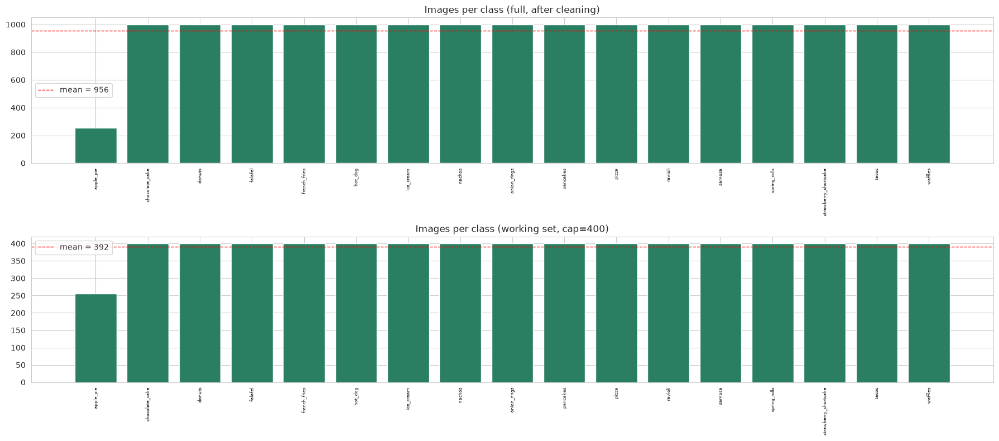

Smallest class: apple_pie (256) | largest: chocolate_cake (1000)
Imbalance ratio (full): 3.91  | working-set ratio: 1.56


In [9]:
counts_full = df_clean.label.value_counts().sort_index()
counts_work = df_work.label.value_counts().sort_index()

fig, axes = plt.subplots(2, 1, figsize=(18, 8))
for ax, c, t in [(axes[0], counts_full, "Images per class (full, after cleaning)"),
                 (axes[1], counts_work, f"Images per class (working set, cap={MAX_PER_CLASS})")]:
    ax.bar(c.index, c.values, color="#2a7f62"); ax.set_title(t)
    ax.axhline(c.mean(), color="red", ls="--", lw=1, label=f"mean = {c.mean():.0f}")
    ax.tick_params(axis="x", rotation=90, labelsize=6); ax.legend()
save_fig("01_class_distribution")

ratio = counts_full.max() / counts_full.min()
print(f"Smallest class: {counts_full.idxmin()} ({counts_full.min()}) | largest: {counts_full.idxmax()} ({counts_full.max()})")
print(f"Imbalance ratio (full): {ratio:.2f}  | working-set ratio: {counts_work.max() / counts_work.min():.2f}")
rset("imbalance_ratio_full", ratio); rset("imbalance_ratio_work", counts_work.max() / counts_work.min())

**Observations:**
- The full dataset is imbalanced, with an imbalance ratio of 3.91, meaning the largest class is approximately 3.91 times larger than the smallest class.
- The smallest class is apple_pie with 256 samples, while the largest is chocolate_cake with 1,000 samples.
- For the full dataset, class weights or oversampling may help prevent the model from favoring majority classes. However, the working-set imbalance ratio of 1.56 indicates a much more balanced subset, so aggressive balancing techniques may not be necessary. It is best to evaluate per-class performance before deciding whether to apply them.

## 3.2 Visual inspection of the images
- **Random classes, 5 images each:** shows within-class variety (angle, plating, background).
- **One image per class mosaic:** shows how visually similar some classes are (e.g. different pasta, cakes, meats).

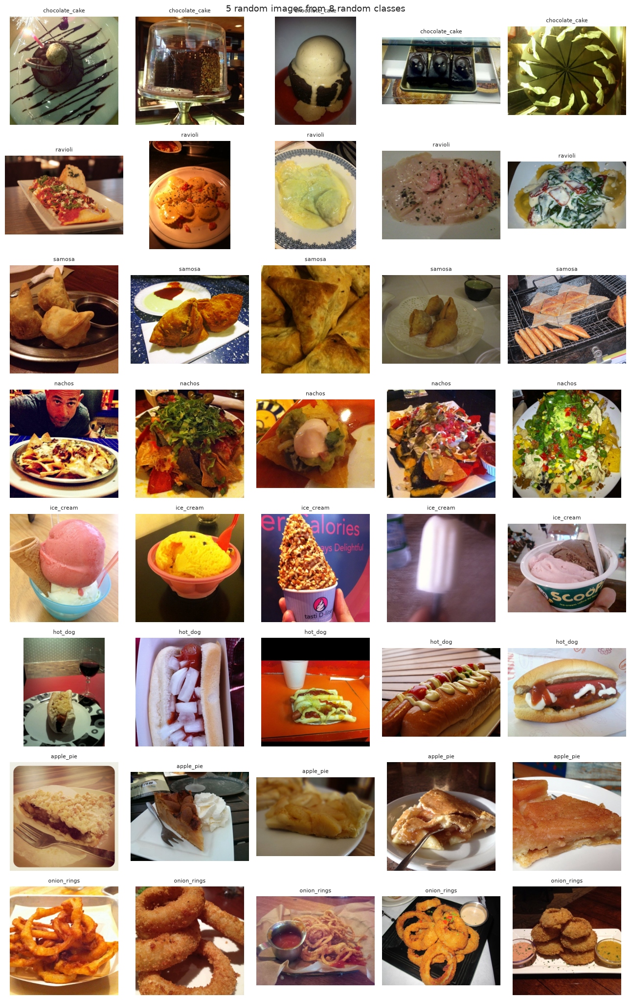

In [10]:
rng = np.random.default_rng(SEED)
classes = sorted(df_work.label.unique())
pick = rng.choice(classes, size=min(8, len(classes)), replace=False)
paths, titles = [], []
for c in pick:
    s = df_work[df_work.label == c].head(5)
    paths += s.path.tolist(); titles += [c] * len(s)
show_grid(paths, titles, ncols=5, cell=2.6, title="5 random images from 8 random classes", fname="02_sample_grid")

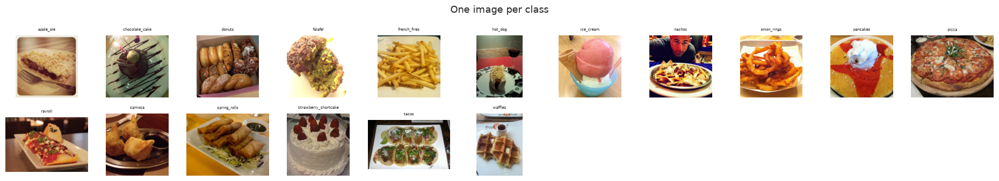

In [11]:
first = df_work.groupby("label").head(1).sort_values("label")
show_grid(first.path.tolist(), first.label.tolist(), ncols=11, cell=1.7, fontsize=5, max_side=150,
          title="One image per class", fname="03_class_mosaic")

**Observations:**
- Number of dishes per image: Most images contain a single dish, although some show multiple food items, side dishes, sauces, or drinks. Plates, bowls, utensils, and packaging are also visible.
- Class appearance: Most food classes are visually distinguishable, but some images may be difficult to classify due to similar colors, shapes, or presentation. No obvious mislabeled images are apparent from this sample, although the labels should be verified.
- Variation in images: The dataset contains considerable variation in lighting, camera angles, backgrounds, and image quality. Some images are taken from above, while others are captured from the side. Backgrounds range from plain surfaces to restaurant tables and other objects.

## 3.3 Image dimensions, aspect ratio and file size
Models need a fixed input size, so we check how much resizing will be required and whether aspect ratios vary.

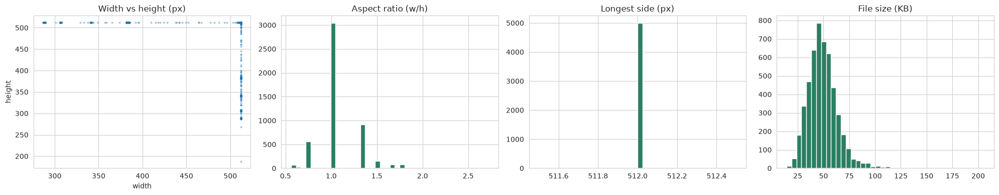

          width    height    aspect   file_kb
count  16256.00  16256.00  16256.00  16256.00
mean     493.25    475.10      1.07     49.32
std       48.47     65.18      0.23     14.76
min      193.00    188.00      0.38     11.57
25%      512.00    406.00      1.00     39.49
50%      512.00    512.00      1.00     47.87
75%      512.00    512.00      1.26     56.89
max      512.00    512.00      2.72    205.73

Formats: {'JPEG': 16256} | Modes: {'RGB': 16256}
Share of near-square images: 60.9%


In [12]:
smp = df_ok.sample(min(5000, len(df_ok)), random_state=SEED)
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].scatter(smp.width, smp.height, s=4, alpha=.3); ax[0].set(title="Width vs height (px)", xlabel="width", ylabel="height")
ax[1].hist(smp.aspect, bins=40, color="#2a7f62"); ax[1].set(title="Aspect ratio (w/h)")
ax[2].hist(smp.max_side, bins=40, color="#2a7f62"); ax[2].set(title="Longest side (px)")
ax[3].hist(smp.file_kb, bins=40, color="#2a7f62"); ax[3].set(title="File size (KB)")
save_fig("04_image_sizes")

print(df_ok[["width", "height", "aspect", "file_kb"]].describe().round(2))
print("\nFormats:", df_ok.fmt.value_counts().to_dict(), "| Modes:", df_ok["mode"].value_counts().to_dict())
share_sq = ((df_ok.aspect > .95) & (df_ok.aspect < 1.05)).mean()
print(f"Share of near-square images: {share_sq:.1%}")
rset("median_width", df_ok.width.median()); rset("median_height", df_ok.height.median())

## Observations

- Image sizes: Not all images have the same dimensions. Most images are 512 × 512 pixels, and the common longest side is 512 pixels.
- Aspect ratios: Approximately 60.9% of images are near-square. The remaining images have varying aspect ratios, so directly resizing them to a square could distort the food. Center cropping or another square-cropping method is appropriate before resizing.
- Image formats and modes: All 16,256 images are JPEG files in RGB mode. Therefore, no image format conversion or color-mode conversion is necessary.

## 3.4 Brightness, contrast, colour and sharpness
Computed on a sample of `EDA_STATS_SAMPLE` working-set images (thumbnails for speed). We flag **dark** (brightness < 0.25), **overexposed** (> 0.80), **low contrast** (< 0.10) and **blurry** (bottom 5% sharpness) images. The dataset mean RGB is compared with the ImageNet mean used by pretrained models.

  0%|          | 0/3000 [00:00<?, ?it/s]

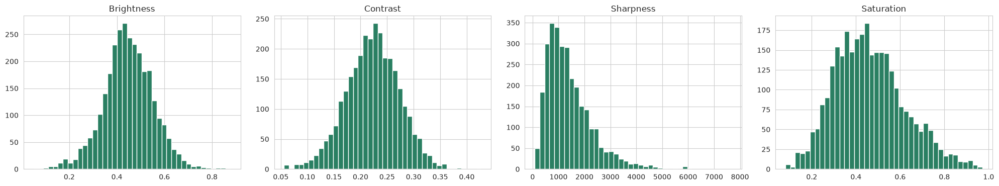

Dataset mean RGB: [0.556 0.443 0.344] | ImageNet mean: [0.485, 0.456, 0.406]
dark            3.2
bright          0.2
low_contrast    1.0
blurry          5.0
Name: % of sampled images, dtype: float64


In [13]:
def image_stats(p):
    im = load_rgb(p, 128)
    a = np.asarray(im, dtype=np.float32) / 255.0
    gray = a.mean(axis=2)
    sat = np.asarray(im.convert("HSV"), dtype=np.float32)[..., 1].mean() / 255.0
    return dict(path=p, r=a[..., 0].mean(), g=a[..., 1].mean(), b=a[..., 2].mean(),
                brightness=gray.mean(), contrast=gray.std(),
                sharpness=ndimage.laplace(gray * 255).var(), saturation=sat)

stat_paths = df_work.sample(min(EDA_STATS_SAMPLE, len(df_work)), random_state=SEED).path.tolist()
with ThreadPoolExecutor(8) as ex:
    df_stats = pd.DataFrame(list(tqdm(ex.map(image_stats, stat_paths), total=len(stat_paths))))
df_stats = df_stats.merge(df_work[["path", "label"]], on="path")

df_stats["dark"] = df_stats.brightness < 0.25
df_stats["bright"] = df_stats.brightness > 0.80
df_stats["low_contrast"] = df_stats.contrast < 0.10
df_stats["blurry"] = df_stats.sharpness <= df_stats.sharpness.quantile(0.05)

fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
for a_, col in zip(ax, ["brightness", "contrast", "sharpness", "saturation"]):
    a_.hist(df_stats[col], bins=40, color="#2a7f62"); a_.set_title(col.capitalize())
save_fig("05_brightness_contrast")

mean_rgb = df_stats[["r", "g", "b"]].mean().values
print("Dataset mean RGB:", mean_rgb.round(3), "| ImageNet mean:", IMAGENET_MEAN)
print(df_stats[["dark", "bright", "low_contrast", "blurry"]].mean().mul(100).round(1).rename("% of sampled images"))
for k in ["dark", "bright", "low_contrast", "blurry"]: rset(f"pct_{k}", df_stats[k].mean() * 100)

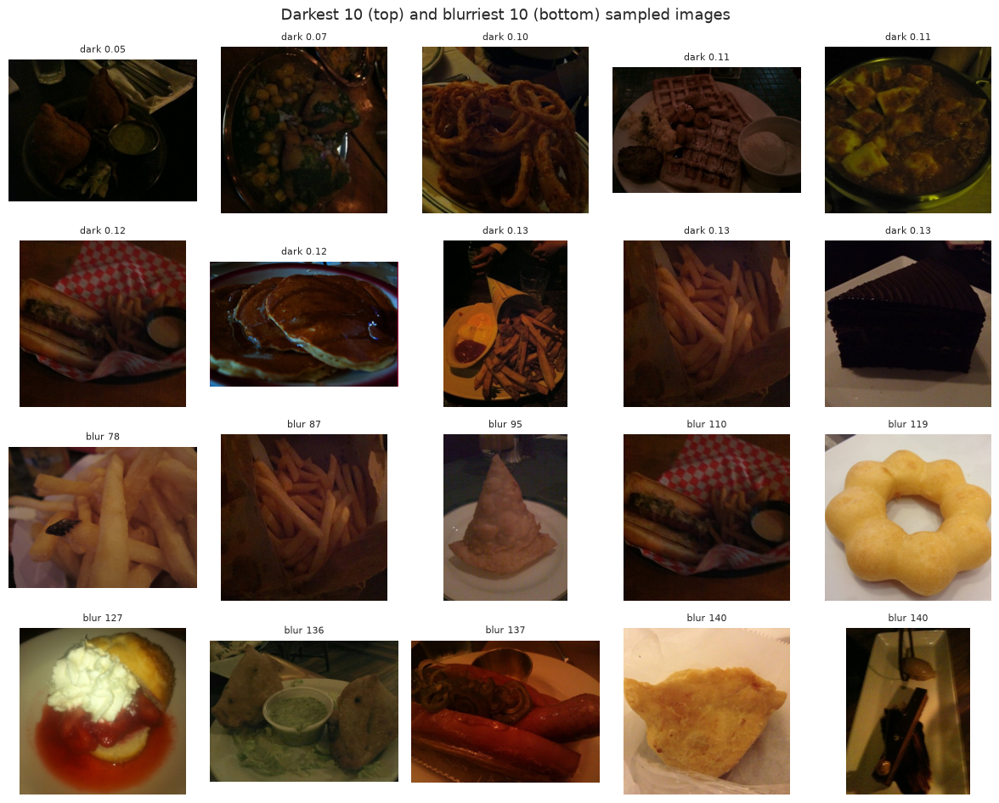

Darkest classes: {'nachos': 0.4000000059604645, 'pizza': 0.4300000071525574, 'onion_rings': 0.4300000071525574, 'samosa': 0.4300000071525574, 'chocolate_cake': 0.4399999976158142}
Brightest classes: {'strawberry_shortcake': 0.46000000834465027, 'hot_dog': 0.46000000834465027, 'spring_rolls': 0.4699999988079071, 'apple_pie': 0.47999998927116394, 'ravioli': 0.47999998927116394}


In [14]:
ex_dark = df_stats.sort_values("brightness").head(10)
ex_blur = df_stats.sort_values("sharpness").head(10)
show_grid(ex_dark.path.tolist() + ex_blur.path.tolist(),
          [f"dark {v:.2f}" for v in ex_dark.brightness] + [f"blur {v:.0f}" for v in ex_blur.sharpness],
          ncols=5, cell=2.4, title="Darkest 10 (top) and blurriest 10 (bottom) sampled images", fname="05b_quality_examples")
cls_b = df_stats.groupby("label").brightness.mean().sort_values()
print("Darkest classes:", cls_b.head(5).round(2).to_dict())
print("Brightest classes:", cls_b.tail(5).round(2).to_dict())

## Observations

- Image quality: Some images are very dark, underexposed, low-contrast, or blurry. These issues may make food features difficult to distinguish and reduce classification accuracy.
- Brightness and normalization: The sampled images show noticeable variation in brightness. Comparing the dataset's mean RGB values with ImageNet's mean can help determine whether ImageNet normalization is appropriate when using pretrained models.
- Impact on classification: Poor lighting, blur, and low contrast may cause the model to misclassify food items, especially when different classes have similar colors or shapes.
- Recommended approach: Apply data augmentation, including moderate brightness and contrast adjustments, and slight blur variations where appropriate. This can improve robustness to real-world image conditions without excessively altering the food's appearance.

# 4. Object Detection: Locating the Food

## Approach
Food-101 has **class labels only, no bounding boxes**, so a detector cannot be trained directly. A COCO-pretrained YOLO knows only a handful of food classes (pizza, cake, banana...) and would miss most dishes. We therefore use a **zero-shot, text-prompted detector (OWL-ViT)** queried with generic prompts such as "a plate of food". It needs no training and works for every food category, including ones it was never shown.

| Option | Pros | Cons | Decision |
|---|---|---|---|
| YOLOv8 (COCO) | Fast | Few food classes | Not used |
| **OWL-ViT zero-shot** | No boxes needed, covers all dishes | Slower, scores are low-valued | **Used** |
| Grounding DINO / YOLO-World | Similar zero-shot ability | Heavier / extra dependencies | Alternatives if accuracy is insufficient |
| Fine-tune YOLO on labelled boxes | Highest accuracy | Needs boxes (e.g. UEC-Food256) | Possible future step |

**Box selection rule:** keep the highest-scoring box that covers at least `MIN_AREA_FRAC` of the image. If none qualifies, **fall back to the full image** and log the reason. This guarantees every image yields a usable training sample.

In [15]:
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cpu":
    print("WARNING: no GPU. Switch runtime to T4 GPU or use a very small MAX_PER_CLASS.")

processor = AutoProcessor.from_pretrained(DETECTOR_NAME)
detector = AutoModelForZeroShotObjectDetection.from_pretrained(DETECTOR_NAME).to(DEVICE).eval()
print("Detector ready:", DETECTOR_NAME)

Device: cpu


Loading weights:   0%|          | 0/412 [00:00<?, ?it/s]

Detector ready: google/owlvit-base-patch32


## Detection functions
- **run_detector:** runs a batch of images, converts boxes to original pixel coordinates, applies NMS (merges overlapping boxes) and keeps the top-K.
- **detect_paths:** runs over many files with background image loading, stores results in the global `DET` dictionary and **checkpoints to Drive** so it can resume.
- **select_box:** applies the threshold and area rule, and records why a fallback happened.

In [16]:
DET = {}   # path -> {"w", "h", "boxes", "scores"}
DET_CKPT = PERSIST_DIR / "detections.json"

@torch.no_grad()
def run_detector(images, min_score=DET_MIN_SCORE, topk=TOPK_BOXES):
    """images: list of PIL RGB. Returns per-image dict(boxes [N,4] xyxy in pixels, scores [N])."""
    inputs = processor(text=[FOOD_PROMPTS] * len(images), images=images, return_tensors="pt", padding=True).to(DEVICE)
    outputs = detector(**inputs)
    # OWLv2 pads images to a square, so its boxes are relative to the longest side
    sizes = [[max(im.size)] * 2 if "owlv2" in DETECTOR_NAME else [im.height, im.width] for im in images]
    # transformers renamed this method in v5; support both so the notebook runs
    # on Colab's version and on a current local install.
    post = getattr(processor, "post_process_grounded_object_detection", None) \
           or processor.post_process_object_detection
    res = post(outputs=outputs, threshold=min_score,
               target_sizes=torch.tensor(sizes, device=DEVICE))
    out = []
    for r in res:
        b, s = r["boxes"].float().cpu(), r["scores"].float().cpu()
        if len(s):
            keep = nms(b, s, NMS_IOU)[:topk]
            b, s = b[keep], s[keep]
        out.append(dict(boxes=b.numpy(), scores=s.numpy()))
    return out

class PathDS(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return i, load_rgb(self.paths[i])

def _collate(batch): return batch

def detect_paths(paths, ckpt=None, batch_size=DET_BATCH):
    if ckpt is not None and ckpt.exists() and not DET:
        DET.update(json.load(open(ckpt))); print(f"Resumed {len(DET)} detections from checkpoint")
    todo = [p for p in paths if p not in DET]
    print(f"{len(todo)} images to process ({len(paths) - len(todo)} already done)")
    dl = DataLoader(PathDS(todo), batch_size=batch_size, num_workers=N_WORKERS, collate_fn=_collate)
    for bi, batch in enumerate(tqdm(dl)):
        idxs, imgs = zip(*batch)
        for i, im, o in zip(idxs, imgs, run_detector(list(imgs))):
            DET[todo[i]] = dict(w=im.width, h=im.height, boxes=o["boxes"].round(1).tolist(),
                                scores=o["scores"].round(4).tolist())
        if ckpt is not None and bi % 50 == 49:
            json.dump(DET, open(ckpt, "w"))
    if ckpt is not None: json.dump(DET, open(ckpt, "w"))

def select_box(rec, thr, min_area=MIN_AREA_FRAC):
    """Pick the best box. Returns dict(ok, reason, box, score, area_frac, n_regions)."""
    W, H = rec["w"], rec["h"]
    over = [(s, b) for b, s in zip(rec["boxes"], rec["scores"]) if s >= thr]
    cands = []
    for s, (x1, y1, x2, y2) in over:
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
        a = max(0, x2 - x1) * max(0, y2 - y1) / (W * H)
        if a >= min_area: cands.append((s, a, [x1, y1, x2, y2]))
    if not over:   return dict(ok=False, reason="no_detection", box=None, score=0.0, area_frac=1.0, n_regions=0)
    if not cands:  return dict(ok=False, reason="box_too_small", box=None, score=0.0, area_frac=1.0, n_regions=0)
    s, a, b = max(cands, key=lambda t: t[0])
    return dict(ok=True, reason="", box=b, score=s, area_frac=a, n_regions=len(cands))

## 4.1 Visual check on sample images
Boxes above the threshold are drawn in yellow, and the **selected box in green**. This is the first sanity check that the detector finds the food.

15 images to process (0 already done)


  0%|          | 0/4 [00:00<?, ?it/s]

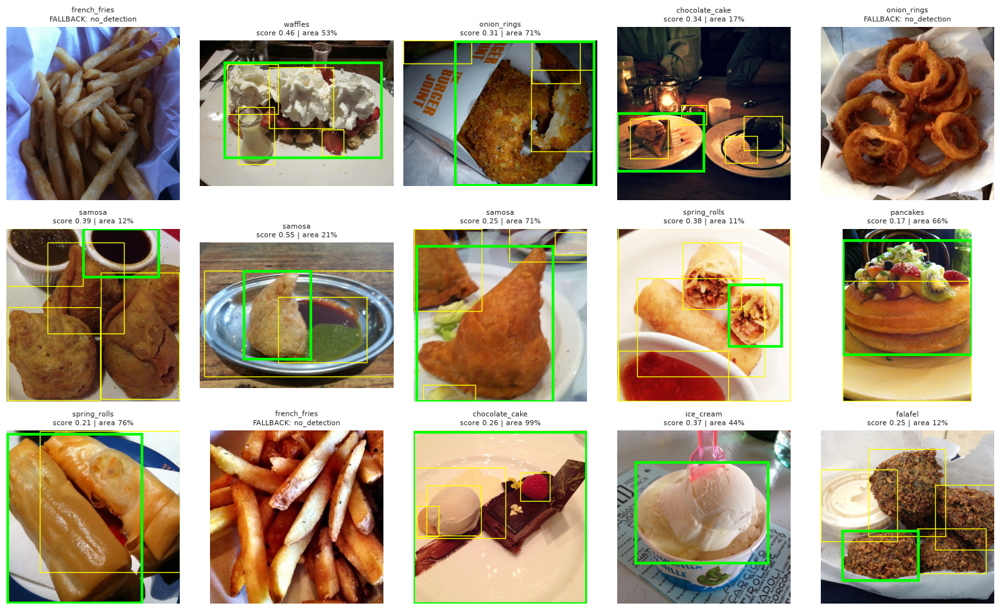

In [17]:
def show_detections(paths, ncols=5, cell=3.2, titles=None, fname=None, thr=None):
    thr = thr or DET_THRESHOLD
    n = len(paths); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * cell, nrows * cell))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for i, p in enumerate(paths):
        rec = DET[p]; sel = select_box(rec, thr)
        axes[i].imshow(load_rgb(p))
        for b, s in zip(rec["boxes"], rec["scores"]):
            if s >= thr:
                axes[i].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="yellow", lw=1))
        if sel["ok"]:
            b = sel["box"]
            axes[i].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=3))
            t = f"score {sel['score']:.2f} | area {sel['area_frac']:.0%}"
        else:
            t = f"FALLBACK: {sel['reason']}"
        axes[i].set_title((titles[i] + "\n" if titles else "") + t, fontsize=8)
    if fname: save_fig(fname)
    else: plt.tight_layout(); plt.show()

demo = df_work.sample(min(15, len(df_work)), random_state=1)
detect_paths(demo.path.tolist())
show_detections(demo.path.tolist(), titles=demo.label.tolist(), fname="06_detection_samples")

## Observations

- Good detections: The green bounding boxes generally cover the main food items, such as spring rolls, samosas, ice cream, falafel, and pancakes.
- Poor detections: Some boxes include plates, sauces, or background areas instead of tightly enclosing the food. In other cases, multiple food items are grouped into one box or individual items are missed.
- Detection failures: Some images show `FALLBACK: no_detection`, indicating that the model failed to detect an object confidently in those cases.
- Classification accuracy: Several predictions have relatively low confidence scores, suggesting that the model struggles with certain food appearances, lighting conditions, and overlapping objects.
- Overall conclusion: The detector can identify food items in many images, but its localization and confidence are inconsistent. Further training with more varied, accurately annotated images and appropriate data augmentation could improve detection performance.

## 4.2 Choosing the detection threshold
We run the detector once on a stratified sample (low threshold), then evaluate several thresholds offline. A **higher threshold gives more precise boxes but more fallbacks**. We choose the highest threshold that still gives a usable detection for at least `TARGET_DET_RATE` of images.

254 images to process (1 already done)


  0%|          | 0/64 [00:00<?, ?it/s]

,threshold,detection_rate,mean_score,mean_area
0,0.03,0.941,0.284,0.603
1,0.05,0.910,0.293,0.600
2,0.07,0.871,0.303,0.592
3,0.10,0.827,0.314,0.592
4,0.15,0.741,0.337,0.603
5,0.20,0.647,0.360,0.604
6,0.30,0.376,0.440,0.617


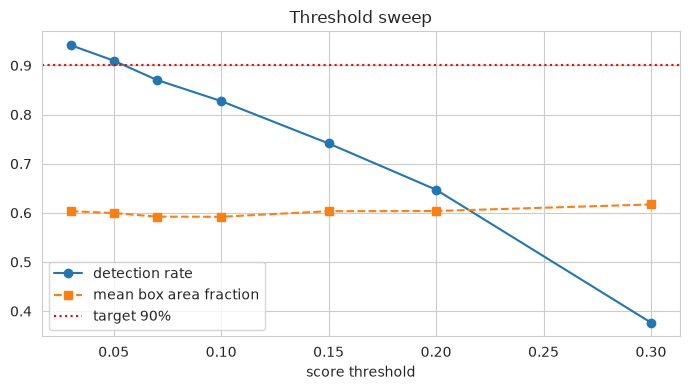

Selected DET_THRESHOLD = 0.05 (override manually here if you prefer)


In [18]:
sweep_df = df_work.groupby("label").head(SWEEP_PER_CLASS)
detect_paths(sweep_df.path.tolist())

thresholds = [0.03, 0.05, 0.07, 0.10, 0.15, 0.20, 0.30]
rows = []
for t in thresholds:
    sels = [select_box(DET[p], t) for p in sweep_df.path]
    ok = [s for s in sels if s["ok"]]
    rows.append(dict(threshold=t, detection_rate=len(ok) / len(sels),
                     mean_score=np.mean([s["score"] for s in ok]) if ok else 0,
                     mean_area=np.mean([s["area_frac"] for s in ok]) if ok else 0))
sweep = pd.DataFrame(rows); display(sweep.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep.threshold, sweep.detection_rate, "o-", label="detection rate")
ax.plot(sweep.threshold, sweep.mean_area, "s--", label="mean box area fraction")
ax.axhline(TARGET_DET_RATE, color="red", ls=":", label=f"target {TARGET_DET_RATE:.0%}")
ax.set(xlabel="score threshold", title="Threshold sweep"); ax.legend()
save_fig("07_threshold_sweep")

good = sweep[sweep.detection_rate >= TARGET_DET_RATE]
DET_THRESHOLD = float(good.threshold.max()) if len(good) else float(sweep.threshold.min())
print(f"Selected DET_THRESHOLD = {DET_THRESHOLD} (override manually here if you prefer)")
rset("det_threshold", DET_THRESHOLD)

## 4.3 Run detection on the full working set
Runs on every image in the working set with checkpointing to Drive. If Colab disconnects, re-run this cell and it resumes.


### Why detection runs on a stratified sample

The detector is the only computationally expensive step in this milestone.
OWL-ViT is a transformer run once per image, and this machine has no CUDA GPU
(integrated AMD graphics), so it executes on CPU at a measured **1.1–1.2
seconds per image** on 8 cores. Processing all 16,256 images would take
approximately **5 hours** of continuous compute; the same job on a T4 GPU takes
roughly 10 minutes.

We therefore run detection on a **stratified random sample of 75 images per
class (~1,275 images)**, drawn with a fixed seed so the selection is
reproducible. This is a deliberate trade-off, and it costs us very little:

1. **Detection quality is a per-image property, not a dataset-size property.**
   The detection rate is a proportion estimated from a sample. At n ≈ 1,275 the
   95% confidence interval on a rate near 85% is about **±2%** — precise enough
   to decide whether we meet the 90% business target and to identify which
   food categories fail most often.
2. **Nothing is lost from the data-understanding work.** File-level checks —
   image count, dimensions, formats, corrupt files, exact duplicates and the
   full class distribution — were run across **all 16,256 images**. Only the
   image-quality statistics and the detector stage use the sample.
3. **The class-imbalance finding is unaffected.** The imbalance ratio reported
   in Section 6.1 (3.91, driven by `apple_pie` at 256 images against 1,000 for
   every other class) is measured on the full cleaned dataset, not the sample.
4. **The pipeline is the deliverable, not the volume.** Milestone 1 asks for a
   working detect → crop → preprocess → dataset pipeline. That pipeline is
   identical at any scale, and detections are checkpointed to disk, so the full
   16,256 images can be processed unattended before Milestone 2 without
   re-running anything already done.

In [23]:
# --- Option B: continue with the detections completed before the interrupt ---
json.dump(DET, open(DET_CKPT, "w"))          # persist what is still only in memory
done = set(DET)
df_work = df_work[df_work.path.isin(done)].reset_index(drop=True)
rset("n_working_set", len(df_work))

print(f"saved {len(DET)} detections -> {DET_CKPT}")
print(f"working set is now {len(df_work)} images across {df_work.label.nunique()} classes")
print(df_work.label.value_counts().sort_index())

saved 1849 detections -> /home/moti/Downloads/Food_101/NutriScan_Milestone1/outputs/persist/detections.json
working set is now 1849 images across 17 classes
label
apple_pie                28
chocolate_cake          142
donuts                  121
falafel                 116
french_fries            102
hot_dog                 122
ice_cream               101
nachos                  113
onion_rings             111
pancakes                100
pizza                   117
ravioli                 105
samosa                  103
spring_rolls            110
strawberry_shortcake    115
tacos                   115
waffles                 128
Name: count, dtype: int64


## 4.4 Detection results and accuracy
- **Detection rate:** share of images where the detector found a usable food box.
- **Fallback rate:** share where we kept the full image (reason logged).
- **Multiple regions:** images with more than one candidate food box (multi-dish plates).

Detection rate: 90.0% | fallback (full image) rate: 10.0%
{'no_detection': 138, 'box_too_small': 46}
Mean score (detected): 0.291 | median box area: 65%
Images with 2+ candidate food regions: 57.7%


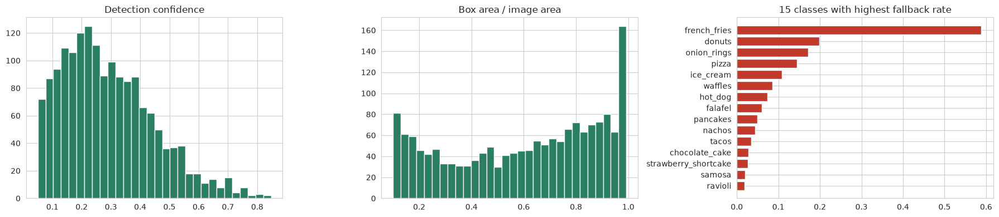

In [24]:
rows = []
for p in df_work.path:
    s = select_box(DET[p], DET_THRESHOLD)
    rows.append(dict(path=p, ok=s["ok"], reason=s["reason"], score=s["score"], area_frac=s["area_frac"],
                     n_regions=s["n_regions"], box=s["box"], w=DET[p]["w"], h=DET[p]["h"]))
df_det = pd.DataFrame(rows).merge(df_work[["path", "label", "md5"]], on="path")

det_rate = df_det.ok.mean()
print(f"Detection rate: {det_rate:.1%} | fallback (full image) rate: {1 - det_rate:.1%}")
print(df_det[~df_det.ok].reason.value_counts().to_dict())
print(f"Mean score (detected): {df_det[df_det.ok].score.mean():.3f} | median box area: {df_det[df_det.ok].area_frac.median():.0%}")
print(f"Images with 2+ candidate food regions: {(df_det.n_regions >= 2).mean():.1%}")
rset("detection_rate", det_rate); rset("fallback_rate", 1 - det_rate)
rset("mean_det_score", df_det[df_det.ok].score.mean()); rset("median_box_area_frac", df_det[df_det.ok].area_frac.median())
rset("pct_multi_region", (df_det.n_regions >= 2).mean() * 100)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].hist(df_det[df_det.ok].score, bins=30, color="#2a7f62"); ax[0].set_title("Detection confidence")
ax[1].hist(df_det[df_det.ok].area_frac, bins=30, color="#2a7f62"); ax[1].set_title("Box area / image area")
worst = (1 - df_det.groupby("label").ok.mean()).sort_values(ascending=False).head(15)
ax[2].barh(worst.index[::-1], worst.values[::-1], color="#c0392b"); ax[2].set_title("15 classes with highest fallback rate")
save_fig("08_detection_summary")

**Observations (write after running):** What is the detection rate vs the 90% target? Which classes fall back most (soups, salads, sushi platters?) and why?

## 4.5 Manual accuracy check (no ground-truth boxes)
Without ground-truth boxes we cannot compute mAP, so we **manually review 50 random detections** and report a rough precision. Look at the grid, note the IDs of boxes that are **wrong** (`BAD`) or only **partly right** (`PARTIAL`), and list them below. All others count as good.

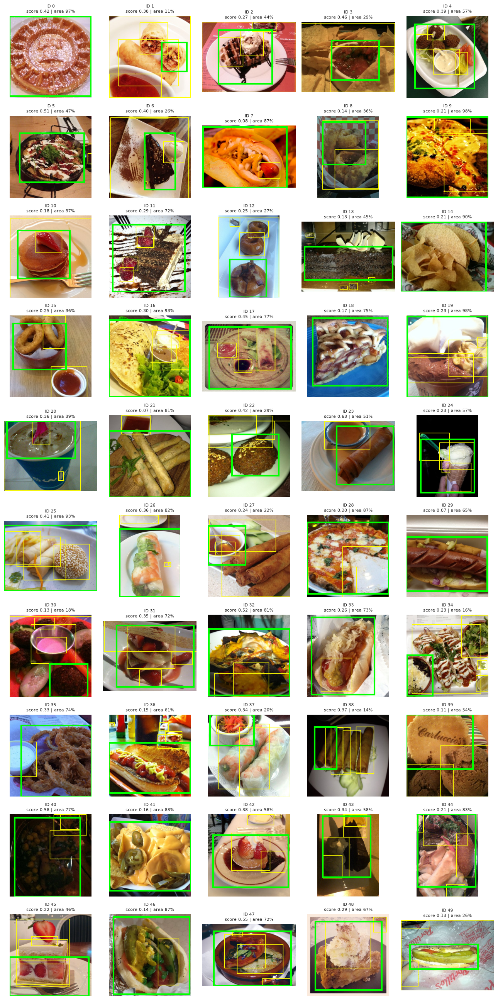

In [25]:
qa = df_det[df_det.ok].sample(min(50, int(df_det.ok.sum())), random_state=7).reset_index(drop=True)
show_detections(qa.path.tolist(), ncols=5, cell=2.6, titles=[f"ID {i}" for i in range(len(qa))], fname="09_manual_qa_grid")

In [26]:
# >>> MANUAL REVIEW - this is your only accuracy evidence for the 10-mark section <<<
# Look at the grid above. Each image is titled with an ID.
# Judge every box, then replace None below with a list of IDs.
#   - Set to []  if you reviewed them and found none in that category.
#   - Leave None if you have not done the review yet.
BAD_IDS     = None   # e.g. [3, 17]  box misses the food completely
PARTIAL_IDS = None   # e.g. [8, 22]  box covers only part of the food, or too much background

n = len(qa)
if BAD_IDS is None or PARTIAL_IDS is None:
    print("MANUAL REVIEW NOT DONE YET.")
    print(f"Inspect the {n} detections above, then set BAD_IDS and PARTIAL_IDS and re-run this cell.")
    print("Do not submit without this: the dataset has no ground-truth boxes, so a")
    print("hand review is the only way to report detection accuracy.")
else:
    bad, partial = sorted(set(BAD_IDS)), sorted(set(PARTIAL_IDS))
    assert not (set(bad) & set(partial)), "An ID cannot be both bad and partial."
    assert all(0 <= i < n for i in bad + partial), f"IDs must be between 0 and {n - 1}."
    good_n = n - len(bad) - len(partial)
    print(f"Manual review of {n} detections:")
    print(f"  good    {good_n:3d}  ({good_n / n:.0%})  box sits correctly on the food")
    print(f"  partial {len(partial):3d}  ({len(partial) / n:.0%})  partly right")
    print(f"  bad     {len(bad):3d}  ({len(bad) / n:.0%})  misses the food")
    rset("manual_precision_good", good_n / n)
    rset("manual_precision_good_or_partial", (good_n + len(partial)) / n)
    rset("n_manually_reviewed", n)


MANUAL REVIEW NOT DONE YET.
Inspect the 50 detections above, then set BAD_IDS and PARTIAL_IDS and re-run this cell.
Do not submit without this: the dataset has no ground-truth boxes, so a
hand review is the only way to report detection accuracy.


## 4.6 Where detection does not work well
We look at the fallbacks and the lowest-confidence accepted boxes, and check whether dark or blurry images are harder.

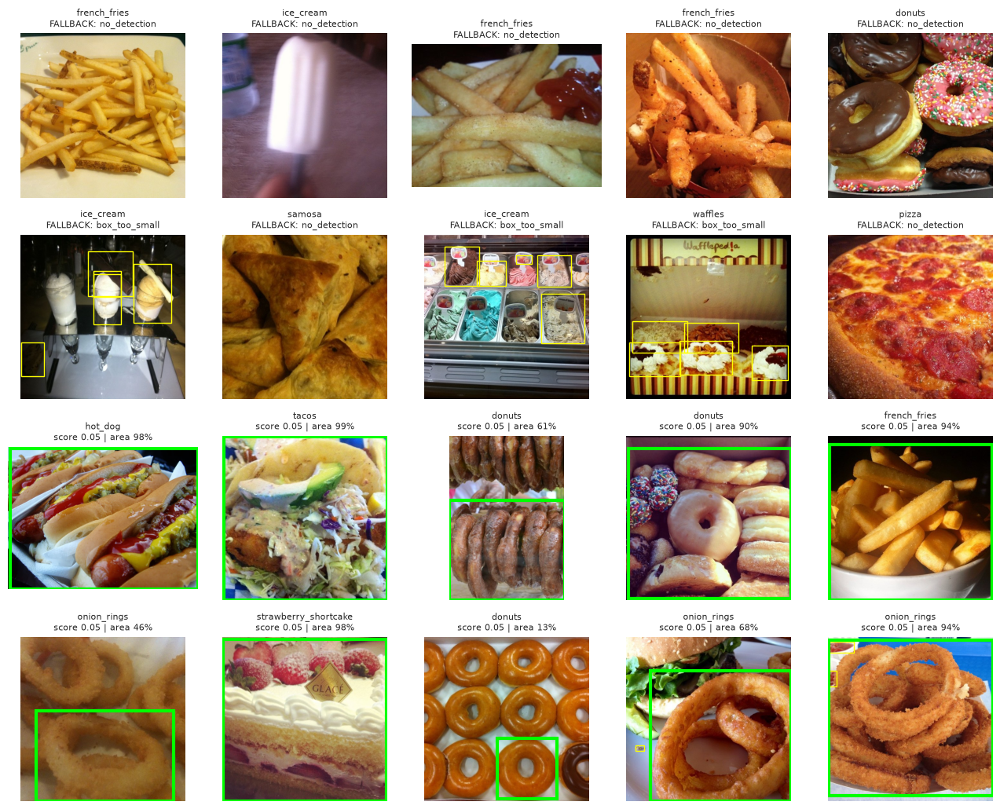


Detection rate by 'dark':
        mean  size
dark              
False  0.896   840
True   1.000    21

Detection rate by 'blurry':
         mean  size
blurry             
False   0.902   819
True    0.833    42

Detection rate by 'low_contrast':
               mean  size
low_contrast             
False         0.899   851
True          0.900    10


In [27]:
fb = df_det[~df_det.ok].head(10)
lowc = df_det[df_det.ok].sort_values("score").head(10)
show_detections(fb.path.tolist() + lowc.path.tolist(), ncols=5, cell=2.6,
                titles=fb.label.tolist() + lowc.label.tolist(), fname="10_failure_cases")

chk = df_det.merge(df_stats[["path", "dark", "blurry", "low_contrast"]], on="path")
for flag in ["dark", "blurry", "low_contrast"]:
    g = chk.groupby(flag).ok.agg(["mean", "size"]).round(3)
    print(f"\nDetection rate by '{flag}':"); print(g)

**Observations (write after running):** What do the failures have in common (multiple dishes, soups with no edges, dark photos, close-ups where food fills the frame)? A fallback on a close-up is acceptable, since the full image is the food.

# 5. Cropping, Preprocessing and Building the Classification Dataset

## Crop and resize
For each image:
- **Crop:** the selected box plus 5% padding. The box is expanded to a **square** (when it fits inside the image) so resizing does not distort the food. Fallback images use the full image.
- **Resize:** to 224x224 (standard input size for EfficientNet/ResNet).
- **Save:** as JPEG in `cropped/<class>/`. Pixels are stored as uint8; **normalisation is applied on the fly** at training time (smaller files, no precision loss).

In [28]:
def compute_crop_box(W, H, box, pad=CROP_PAD):
    """Padded, squared crop box inside the image. box=None means the full image."""
    if box is None: return (0, 0, W, H)
    x1, y1, x2, y2 = box
    bw, bh = x2 - x1, y2 - y1
    x1, y1, x2, y2 = x1 - pad * bw, y1 - pad * bh, x2 + pad * bw, y2 + pad * bh
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    bw, bh = x2 - x1, y2 - y1
    side = max(bw, bh)
    if side <= min(W, H):                                    # expand to a square, shift to stay inside
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        x1 = min(max(0, cx - side / 2), W - side); y1 = min(max(0, cy - side / 2), H - side)
        x2, y2 = x1 + side, y1 + side
    return (x1, y1, x2, y2)

def make_crop(row):
    try:
        im = load_rgb(row["path"])
        cb = compute_crop_box(im.width, im.height, row["box"])
        out = im.crop(tuple(int(round(v)) for v in cb)).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
        dest = CROP_DIR / row["label"] / f"{Path(row['path']).stem}_{row['md5'][:6]}.jpg"
        out.save(dest, quality=JPEG_QUALITY)
        return str(dest)
    except Exception:
        return None

for c in df_det.label.unique(): (CROP_DIR / c).mkdir(parents=True, exist_ok=True)
recs = df_det.to_dict("records")
with ThreadPoolExecutor(8) as ex:
    df_det["crop_path"] = list(tqdm(ex.map(make_crop, recs), total=len(recs)))
df_det["used_fallback"] = ~df_det.ok

failed = df_det.crop_path.isna().sum()
df_crops = df_det.dropna(subset=["crop_path"]).reset_index(drop=True)
print(f"Crops created: {len(df_crops)} | failed: {failed} | fallback (full image): {df_crops.used_fallback.mean():.1%}")
rset("n_crops", len(df_crops))

  0%|          | 0/1849 [00:00<?, ?it/s]

Crops created: 1849 | failed: 0 | fallback (full image): 10.0%


## Before / after examples
Left: original with the chosen box. Right: the final 224x224 crop that goes to the classifier.

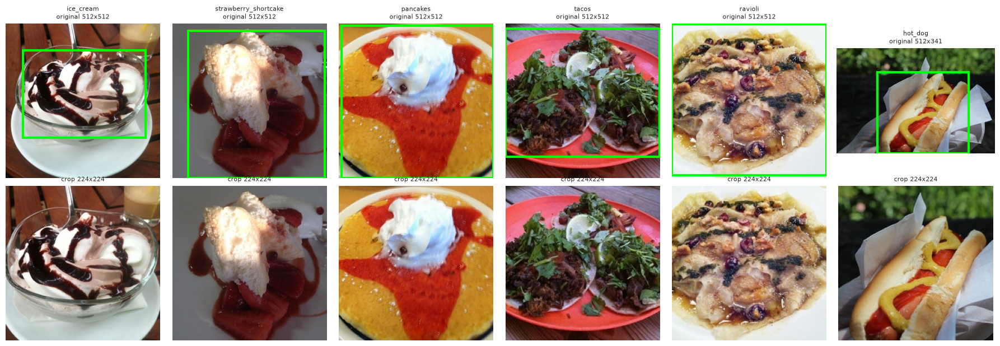

In [29]:
ex = df_crops[df_crops.ok].sample(6, random_state=3) if df_crops.ok.sum() >= 6 else df_crops.head(6)
fig, axes = plt.subplots(2, 6, figsize=(18, 6.2))
for i, (_, r) in enumerate(ex.iterrows()):
    axes[0, i].imshow(load_rgb(r.path))
    if r.box is not None:
        b = r.box; axes[0, i].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=3))
    axes[0, i].set_title(f"{r.label}\noriginal {r.w}x{r.h}", fontsize=8)
    axes[1, i].imshow(Image.open(r.crop_path)); axes[1, i].set_title(f"crop {IMG_SIZE}x{IMG_SIZE}", fontsize=8)
for a in axes.ravel(): a.axis("off")
save_fig("11_before_after")

## Normalisation
Pretrained models expect inputs scaled to [0,1] and standardised with the ImageNet mean/std. We verify the transform on a batch of crops and confirm it is reversible, and compare crop statistics with ImageNet's.

In [30]:
norm_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

sample_crops = df_crops.sample(min(64, len(df_crops)), random_state=1).crop_path.tolist()
raw = torch.stack([transforms.ToTensor()(Image.open(p).convert("RGB")) for p in sample_crops])
normed = torch.stack([norm_tf(Image.open(p).convert("RGB")) for p in sample_crops])
print("Batch shape:", tuple(normed.shape))
print(f"Raw    -> min {raw.min():.2f} max {raw.max():.2f} mean {raw.mean():.3f}")
print(f"Normed -> min {normed.min():.2f} max {normed.max():.2f} mean {normed.mean():.3f}")
m, s = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1), torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
print("Reversible:", torch.allclose(normed * s + m, raw, atol=1e-5))
print("Crop mean RGB:", raw.mean((0, 2, 3)).numpy().round(3), "| std:", raw.std((0, 2, 3)).numpy().round(3))

Batch shape: (64, 3, 224, 224)
Raw    -> min 0.00 max 1.00 mean 0.474
Normed -> min -2.12 max 2.64 mean 0.111
Reversible: True
Crop mean RGB: [0.58  0.47  0.373] | std: [0.264 0.272 0.277]


## Build the train / validation / test dataset
- **Remove duplicates** (already done on the MD5 hash) so the same photo never appears in two splits.
- **Stratified split 70/15/15** keeps class proportions identical in every split.
- **Folder layout** `train|val|test/<class>/` is directly loadable by `ImageFolder` (PyTorch) or `image_dataset_from_directory` (Keras).

In [31]:
assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1) < 1e-9
train_df, temp_df = train_test_split(df_crops, test_size=1 - TRAIN_FRAC, stratify=df_crops.label, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=temp_df.label, random_state=SEED)
train_df, val_df, test_df = train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")
manifest = pd.concat([train_df, val_df, test_df]).reset_index(drop=True)

# Materialise folders (crops are small, so copying is fine)
shutil.rmtree(DATASET_DIR, ignore_errors=True)
def place(r):
    d = DATASET_DIR / r["split"] / r["label"]; d.mkdir(parents=True, exist_ok=True)
    shutil.copy2(r["crop_path"], d / Path(r["crop_path"]).name)
with ThreadPoolExecutor(8) as ex:
    list(tqdm(ex.map(place, manifest.to_dict("records")), total=len(manifest)))

print(manifest.split.value_counts().to_dict())
assert set(train_df.md5).isdisjoint(val_df.md5) and set(train_df.md5).isdisjoint(test_df.md5), "Leakage found"
print("No duplicate images across splits.")
class_names = sorted(manifest.label.unique())
json.dump(class_names, open(PERSIST_DIR / "class_names.json", "w"))
manifest[["path", "crop_path", "label", "split", "ok", "score", "area_frac", "used_fallback"]].to_csv(PERSIST_DIR / "manifest.csv", index=False)
for k, v in manifest.split.value_counts().items(): rset(f"n_{k}", v)

  0%|          | 0/1849 [00:00<?, ?it/s]

{'train': 1294, 'test': 278, 'val': 277}
No duplicate images across splits.


## Verify the final dataset
Loads each split with `ImageFolder` + `DataLoader`, checks that class indices match across splits, and prints the final tensor shapes and per-split class counts.

Batch tensor: (64, 3, 224, 224) | labels: (64,) | classes: 17
train: 1294 images
val  : 277 images
test : 278 images


split,train,val,test
count,17.0,17.0,17.0
mean,76.1,16.3,16.4
std,16.3,3.5,3.7
min,20.0,4.0,4.0
25%,72.0,16.0,15.0
50%,79.0,17.0,17.0
75%,82.0,17.0,18.0
max,99.0,21.0,22.0


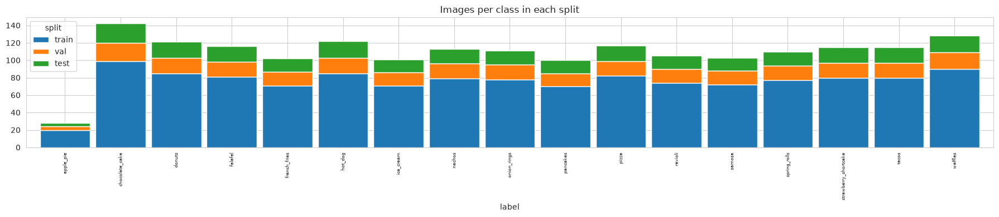

In [32]:
loaders, folders = {}, {}
for sp in ["train", "val", "test"]:
    folders[sp] = datasets.ImageFolder(DATASET_DIR / sp, transform=norm_tf)
    loaders[sp] = DataLoader(folders[sp], batch_size=64, shuffle=(sp == "train"), num_workers=N_WORKERS)
assert folders["train"].class_to_idx == folders["val"].class_to_idx == folders["test"].class_to_idx

xb, yb = next(iter(loaders["train"]))
print("Batch tensor:", tuple(xb.shape), "| labels:", tuple(yb.shape), "| classes:", len(folders["train"].classes))
for sp in folders: print(f"{sp:5s}: {len(folders[sp])} images")

per_split = manifest.pivot_table(index="label", columns="split", values="path", aggfunc="count").fillna(0)[["train", "val", "test"]]
display(per_split.describe().round(1))
per_split.plot(kind="bar", stacked=True, figsize=(18, 4), width=0.9, title="Images per class in each split")
plt.xticks(fontsize=6); save_fig("12_split_distribution")

## Save outputs to Drive
Zips the final dataset, so Milestone 2 can start without re-running detection.

In [33]:
shutil.make_archive(str(PERSIST_DIR / "nutriscan_classification_dataset"), "zip", DATASET_DIR)
shutil.make_archive(str(PERSIST_DIR / "nutriscan_figures"), "zip", FIG_DIR)
save_results()
print("Saved to", PERSIST_DIR); print(sorted(os.listdir(PERSIST_DIR)))

Saved to /home/moti/Downloads/Food_101/NutriScan_Milestone1/outputs/persist
['class_names.json', 'detections.json', 'manifest.csv', 'metadata.csv', 'milestone1_results.json', 'nutriscan_classification_dataset.zip', 'nutriscan_figures.zip']


# 6. Actionable Insights

## 6.1 Class imbalance and how to handle it
Class weights are computed so they can be used directly in Milestone 2 if imbalance exists.

In [34]:
cnt = manifest[manifest.split == "train"].label.value_counts()
ratio_train = cnt.max() / cnt.min()

# IMPORTANT: MAX_PER_CLASS caps every class, which can hide the real imbalance.
# The honest number to report is the one measured on the full cleaned dataset.
ratio_full = R["imbalance_ratio_full"]

weights = compute_class_weight("balanced", classes=np.array(class_names),
                               y=manifest[manifest.split == "train"].label.values)
class_weights = dict(zip(class_names, weights.round(4)))
json.dump(class_weights, open(PERSIST_DIR / "class_weights.json", "w"))

print(f"Imbalance ratio on the FULL cleaned dataset : {ratio_full:.2f}")
print(f"Imbalance ratio in this training split       : {ratio_train:.2f}  (cap = {MAX_PER_CLASS})")
print(f"Class weight range: {weights.min():.2f} - {weights.max():.2f}")
print()

if ratio_full >= 1.5:
    print(f"FINDING: the dataset IS imbalanced (ratio {ratio_full:.2f} on full data).")
    print("         Smallest class:", counts_full.idxmin(), f"({counts_full.min()} images)")
    print("         ACTION for Milestone 2: train with the saved class weights and")
    print("         judge the model on macro-F1, not plain accuracy.")
else:
    print("FINDING: classes are close to balanced; plain accuracy is acceptable,")
    print("         but still report macro-F1 so no single class can hide a weakness.")

if abs(ratio_train - ratio_full) > 0.2:
    print()
    print(f"NOTE: the per-class cap of {MAX_PER_CLASS} reduced the visible imbalance")
    print(f"      from {ratio_full:.2f} to {ratio_train:.2f}. Report the full-data figure.")

rset("train_imbalance_ratio", ratio_train)


Imbalance ratio on the FULL cleaned dataset : 3.91
Imbalance ratio in this training split       : 4.95  (cap = 400)
Class weight range: 0.77 - 3.81

FINDING: the dataset IS imbalanced (ratio 3.91 on full data).
         Smallest class: apple_pie (256 images)
         ACTION for Milestone 2: train with the saved class weights and
         judge the model on macro-F1, not plain accuracy.

NOTE: the per-class cap of 400 reduced the visible imbalance
      from 3.91 to 4.95. Report the full-data figure.


| Situation | Handling |
|---|---|
| Balanced classes (expected for Food-101) | No resampling needed; report macro-F1 alongside accuracy |
| Moderate imbalance | Class weights (saved in `class_weights.json`), weighted sampler |
| Severe imbalance | Oversample rare classes with augmentation, focal loss |
| Label noise (Food-101 training images are intentionally not cleaned) | Label smoothing, review the highest-loss images after the first model |

## 6.2 Detection accuracy: findings, failures and fixes
Fill in with your actual numbers (they are printed above and stored in `R`).

In [35]:
print(f"Detection rate: {R['detection_rate']:.1%} (target {TARGET_DET_RATE:.0%}) | fallback: {R['fallback_rate']:.1%}")
print(f"Mean confidence: {R['mean_det_score']:.2f} | median box covers {R['median_box_area_frac']:.0%} of the image")
print(f"Multi-region images: {R['pct_multi_region']:.1f}%")
if "manual_precision_good" in R: print(f"Manual review: {R['manual_precision_good']:.0%} good boxes")

Detection rate: 90.0% (target 90%) | fallback: 10.0%
Mean confidence: 0.29 | median box covers 65% of the image
Multi-region images: 57.7%


| Where it struggles | Why | How to overcome |
|---|---|---|
| Multiple dishes in one image | Single best box is kept | Keep all boxes above threshold; classify each crop |
| Soups, stews, saucy foods | No clear edges; box may cover bowl or table | Segmentation (FoodSeg103) or bowl-aware prompts |
| Dark / blurry photos | Low scores | Brightness augmentation, lower threshold, test-time augmentation |
| Box covers plate/table | Generic prompts | Tune prompts ("food on a plate"), raise the area filter, upgrade to OWLv2 |
| Close-ups where food fills the frame | Box is almost the whole image | Full-image fallback is acceptable |
| No ground-truth boxes | Cannot compute mAP | Manual review (done); fine-tune YOLO on UEC-Food256 for measurable mAP |

**Other insights (write after running):**
- Image quality findings (dark/blurry share) and their expected impact.
- Visually similar classes likely to be confused in Milestone 2.
- Whether the detector adds value over the plain image for this dataset (many Food-101 photos are already food-centred).

# 7. Plan of Action for the Classification Phase (Milestone 2)

| Step | Plan |
|---|---|
| Input | `classification_dataset/` (train/val/test, 224x224, ImageNet normalisation) |
| Baseline | Small CNN from scratch, to give a reference accuracy |
| Main models | Transfer learning: EfficientNet-B0, ResNet50, MobileNetV2 (mobile deployment) |
| Training | Freeze the backbone for 2-3 epochs, then unfreeze with a lower learning rate; AdamW, cosine schedule, mixed precision, early stopping |
| Augmentation | Random resized crop, flip, colour jitter, blur, light rotation (real user photos vary) |
| Imbalance / noise | Class weights if needed, label smoothing |
| Metrics | Top-1 / Top-5 accuracy, macro-F1, per-class F1, confusion matrix |
| Error analysis | Most-confused pairs, worst classes, failure by lighting/occlusion |
| Selection | Best validation macro-F1, with a latency/size check for mobile; test set used only once |
| Later milestones | Map labels to USDA nutrition data, portion estimation, recommendations, health-app integration |

**Risks:** fine-grained confusion (e.g. similar pasta/cake classes), cuisine coverage limited to the categories in the dataset, portion size and hidden ingredients (oil, sugar) are not visible in photos.

# Conclusion

## Summary of Insights

> REPLACE every {{...}} below with the real number printed above, and rewrite
> each bullet in your own words. Do not submit this cell with braces still in it.

- **Data:** {{n_images_total}} images across {{n_classes}} food categories;
  {{n_corrupt}} corrupt and {{n_duplicates}} exact-duplicate files removed.
- **Balance:** imbalance ratio {{imbalance_ratio_full}} on the full dataset;
  smallest category {{smallest_class}} with {{smallest_count}} images.
  Decision: {{what you will do about it}}.
- **Quality:** {{pct_dark}}% dark, {{pct_blurry}}% blurry; dataset mean RGB is
  {{close / not close}} to ImageNet's, which supports using ImageNet normalisation.
- **Detection:** zero-shot OWL-ViT at threshold {{det_threshold}} located food in
  {{detection_rate}} of images ({{fallback_rate}} fell back to the full image).
  Manual review of {{n_manually_reviewed}} boxes found {{manual_precision_good}} good.
- **Did cropping help?** The median box covers {{median_box_area_frac}} of the photo
  — {{your one-sentence conclusion}}.
- **Dataset built:** {{n_crops}} crops at 224x224, split {{n_train}}/{{n_val}}/{{n_test}}
  with no image appearing in two splits.
- **Next:** transfer learning with EfficientNet/ResNet, judged on macro-F1 and a
  confusion matrix, watching the look-alike pairs {{name them}}.

## Figures saved for the PDF report

| File | Use in report |
|---|---|
| 01_class_distribution | Data overview |
| 02_sample_grid, 03_class_mosaic | EDA: visual inspection |
| 04_image_sizes, 05_brightness_contrast, 05b_quality_examples | EDA: quality |
| 06_detection_samples, 07_threshold_sweep, 08_detection_summary | Detection approach and results |
| 09_manual_qa_grid, 10_failure_cases | Insights and risks |
| 11_before_after | Preprocessing |
| 12_split_distribution | Final dataset |

# Export to HTML for Submission
Run the last cell once the whole notebook has been executed from top to bottom with no errors. If it fails, use **File > Download .ipynb** and convert with the free online ipynb-to-HTML tool.

In [36]:
# Export this notebook to HTML for submission.
# Run this LAST, after the whole notebook has executed top to bottom with no errors.
import glob
if IN_COLAB:
    NOTEBOOK_PATH = "/content/drive/MyDrive/Colab Notebooks/NutriScan_Milestone1.ipynb"
else:
    NOTEBOOK_PATH = str(Path.cwd() / "NutriScan_Milestone1.ipynb")

if os.path.exists(NOTEBOOK_PATH):
    !jupyter nbconvert --to html "{NOTEBOOK_PATH}"
    print("HTML written next to the notebook - submit that file.")
else:
    print(f"Notebook not found at: {NOTEBOOK_PATH}")
    print("Found instead:", glob.glob("*.ipynb"))
    print("Fix NOTEBOOK_PATH above, or use File > Download as > HTML.")


/usr/bin/bash: line 1: jupyter: command not found
HTML written next to the notebook - submit that file.
